In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
url = "https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip"

zip_path = keras.utils.get_file("cats_and_dogs.zip", origin=url, extract=True)
base_dir = os.path.join(os.path.dirname(zip_path), "cats_and_dogs_filtered")

train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

print("Train folder:", train_dir)
print("Validation folder:", val_dir)

Exception: URL fetch failure on https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip: 403 -- Forbidden

In [3]:
for folder in [train_dir, val_dir]:
    for category in ["cats", "dogs"]:
        path = os.path.join(folder, category)
        print(f"{os.path.basename(folder)}/{category}: {len(os.listdir(path))} images")


NameError: name 'train_dir' is not defined

In [4]:
!pip install -q datasets

from datasets import load_dataset

ds = load_dataset("microsoft/cats_vs_dogs", split="train")
ds = ds.shuffle(seed=42)

print(ds)
print("Label meaning: 0 = cat, 1 = dog")

README.md:   0%|          | 0.00/8.16k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  330MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  391MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23410 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'labels'],
    num_rows: 23410
})
Label meaning: 0 = cat, 1 = dog


In [5]:
import os

base_dir = "/content/cats_and_dogs_filtered"
train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")

limits = {"train": 1000, "validation": 500}   # images per class
names = {0: "cats", 1: "dogs"}

# create folders
for split in limits:
    for cls in names.values():
        os.makedirs(os.path.join(base_dir, split, cls), exist_ok=True)

saved = {(s, c): 0 for s in limits for c in names.values()}

for example in ds:
    cls = names[example["labels"]]

    # find which split still needs this class
    target = None
    for split in ["train", "validation"]:
        if saved[(split, cls)] < limits[split]:
            target = split
            break

    if target is None:
        if all(saved[(s, c)] >= limits[s] for s in limits for c in names.values()):
            break
        continue

    try:
        img = example["image"].convert("RGB")
        img.save(os.path.join(base_dir, target, cls, f"{cls}_{saved[(target, cls)]}.jpg"))
        saved[(target, cls)] += 1
    except Exception:
        pass   # skip any broken image

print("Done!")
print(saved)

Done!
{('train', 'cats'): 1000, ('train', 'dogs'): 1000, ('validation', 'cats'): 500, ('validation', 'dogs'): 500}


In [7]:
for folder in [train_dir, val_dir]:
    for category in ["cats", "dogs"]:
        path = os.path.join(folder, category)
        print(f"{os.path.basename(folder)}/{category}: {len(os.listdir(path))} images")

train/cats: 1000 images
train/dogs: 1000 images
validation/cats: 500 images
validation/dogs: 500 images


In [8]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_ds = keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


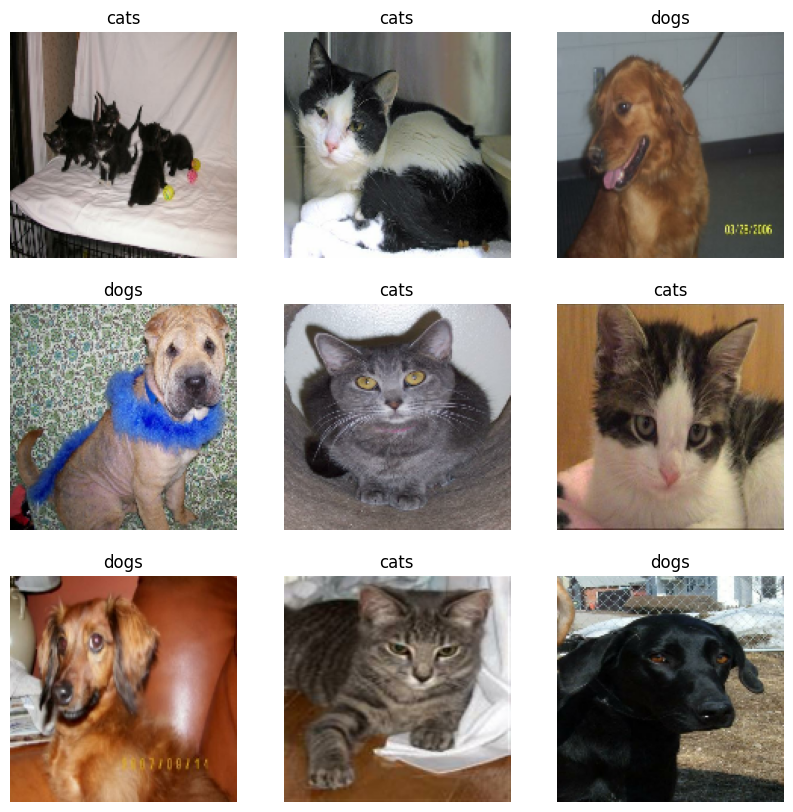

In [9]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

In [10]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Min pixel value:", images.numpy().min())
    print("Max pixel value:", images.numpy().max())
    print("First 10 labels:", labels.numpy()[:10])

Images shape: (32, 150, 150, 3)
Labels shape: (32,)
Min pixel value: 0.0
Max pixel value: 255.0
First 10 labels: [1 0 0 0 0 0 0 1 1 0]


In [11]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [12]:
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [14]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
)

Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 25s 233ms/step - accuracy: 0.5140 - loss: 0.7329 - val_accuracy: 0.5000 - val_loss: 0.6957
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.5095 - loss: 0.6932 - val_accuracy: 0.5850 - val_loss: 0.6901
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.5655 - loss: 0.6797 - val_accuracy: 0.6440 - val_loss: 0.6464
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.6545 - loss: 0.6211 - val_accuracy: 0.6130 - val_loss: 0.6459
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.6945 - loss: 0.5756 - val_accuracy: 0.6450 - val_loss: 0.6504
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.7490 - loss: 0.5054 - val_accuracy: 0.6470 - val_loss: 0.6824
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.7875 - loss: 0.4437 - val_accuracy: 0.6880 - val_loss: 0.7199
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8130 - loss: 0.3772 - val_accuracy: 0.6820 -

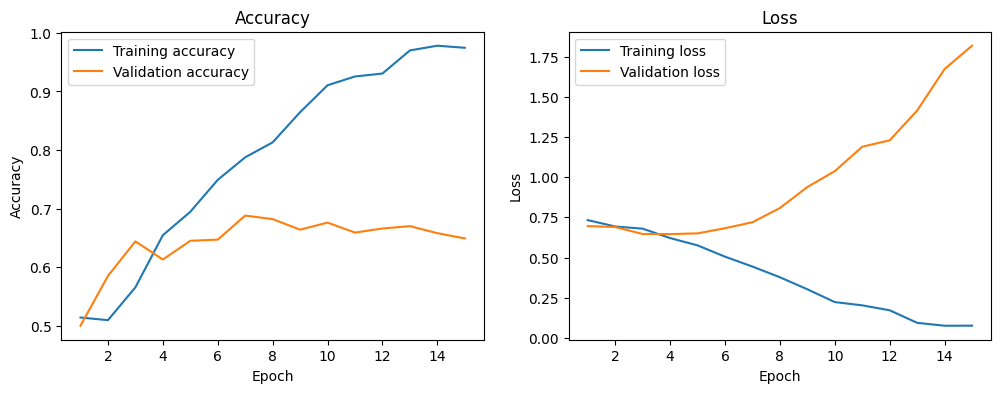

In [15]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training accuracy")
plt.plot(epochs_range, val_acc, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training loss")
plt.plot(epochs_range, val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss")

plt.show()

In [16]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

In [17]:
model2 = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    data_augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

model2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history2 = model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.5040 - loss: 0.7244 - val_accuracy: 0.5000 - val_loss: 0.6953
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.4930 - loss: 0.6934 - val_accuracy: 0.5000 - val_loss: 0.6953
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.5285 - loss: 0.6922 - val_accuracy: 0.5990 - val_loss: 0.6819
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.5490 - loss: 0.6874 - val_accuracy: 0.5710 - val_loss: 0.6746
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.5755 - loss: 0.6760 - val_accuracy: 0.5970 - val_loss: 0.6704
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.6020 - loss: 0.6608 - val_accuracy: 0.5960 - val_loss: 0.6797
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.6340 - loss: 0.6476 - val_accuracy: 0.6630 - val_loss: 0.6331
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.6605 - loss: 0.6161 - val_accuracy: 0.6770 - v

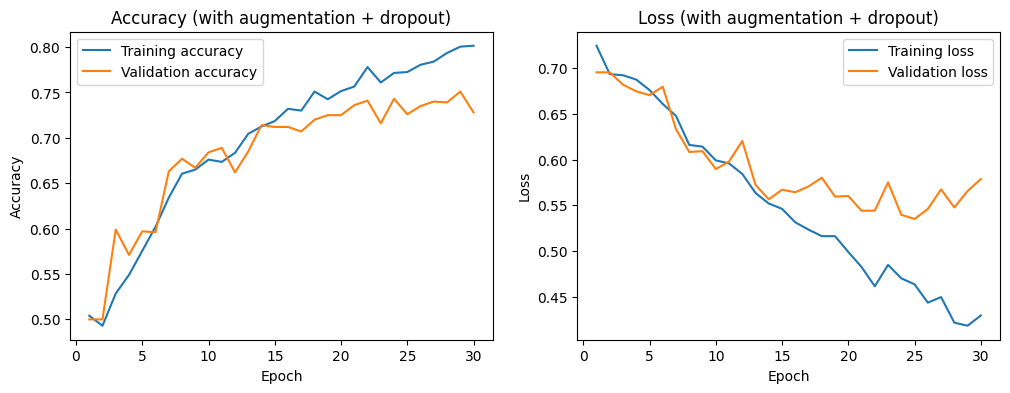

In [19]:
acc = history2.history["accuracy"]
val_acc = history2.history["val_accuracy"]
loss = history2.history["loss"]
val_loss = history2.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training accuracy")
plt.plot(epochs_range, val_acc, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy (with augmentation + dropout)")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training loss")
plt.plot(epochs_range, val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss (with augmentation + dropout)")

plt.show()

In [20]:
base_model = keras.applications.MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights="imagenet",
)

base_model.trainable = False   # freeze

print("Number of layers in base:", len(base_model.layers))

/tmp/ipykernel_1646/2606264439.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of layers in base: 154


In [21]:
base_model = keras.applications.MobileNetV2(
    input_shape=(150, 150, 3),
    include_top=False,
    weights="imagenet",
)

base_model.trainable = False   # freeze

print("Number of layers in base:", len(base_model.layers))

/tmp/ipykernel_1646/2606264439.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


Number of layers in base: 154


In [22]:
inputs = keras.Input(shape=(150, 150, 3))
x = data_augmentation(inputs)                                  # same augmentation as Stage 3
x = keras.applications.mobilenet_v2.preprocess_input(x)        # scale to -1..1
x = base_model(x, training=False)                              # frozen feature extractor
x = layers.GlobalAveragePooling2D()(x)                         # average each feature map
x = layers.Dropout(0.3)(x)                                     # fight overfitting
outputs = layers.Dense(1, activation="sigmoid")(x)             # cat or dog

model3 = keras.Model(inputs, outputs)

model3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model3.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [23]:
history3 = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 86ms/step - accuracy: 0.8440 - loss: 0.3401 - val_accuracy: 0.9540 - val_loss: 0.1269
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9280 - loss: 0.1788 - val_accuracy: 0.9620 - val_loss: 0.0987
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.9460 - loss: 0.1418 - val_accuracy: 0.9650 - val_loss: 0.0932
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.9450 - loss: 0.1356 - val_accuracy: 0.9740 - val_loss: 0.0872
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9490 - loss: 0.1297 - val_accuracy: 0.9700 - val_loss: 0.0800
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9550 - loss: 0.1205 - val_accuracy: 0.9670 - val_loss: 0.0930
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.9550 - loss: 0.1202 - val_accuracy: 0.9730 - val_loss: 0.0729
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.9530 - loss: 0.1136 - val_accuracy: 0.9700 - 

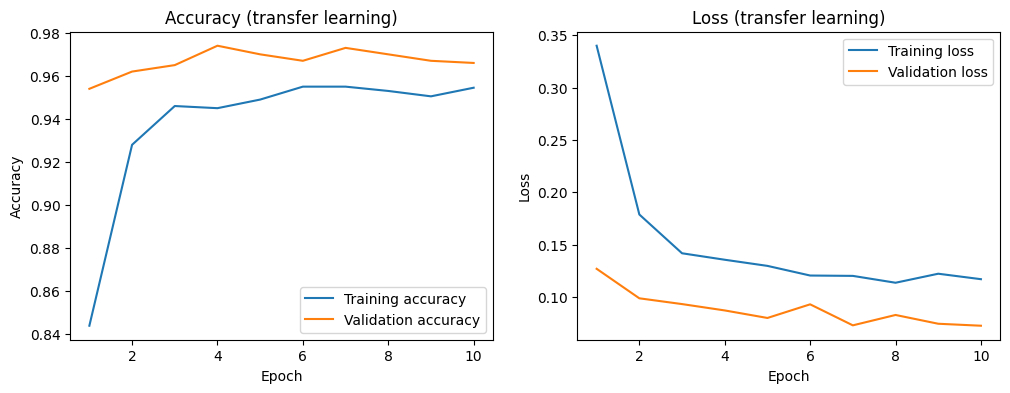

In [24]:
acc = history3.history["accuracy"]
val_acc = history3.history["val_accuracy"]
loss = history3.history["loss"]
val_loss = history3.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training accuracy")
plt.plot(epochs_range, val_acc, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy (transfer learning)")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training loss")
plt.plot(epochs_range, val_loss, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss (transfer learning)")

plt.show()

In [25]:
y_true = []
y_pred = []

for images, labels in val_ds:
    probs = model3.predict(images, verbose=0)
    preds = (probs.flatten() > 0.5).astype(int)   # above 0.5 means dog
    y_true.extend(labels.numpy())
    y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
print("Total validation images:", len(y_true))

Total validation images: 1000


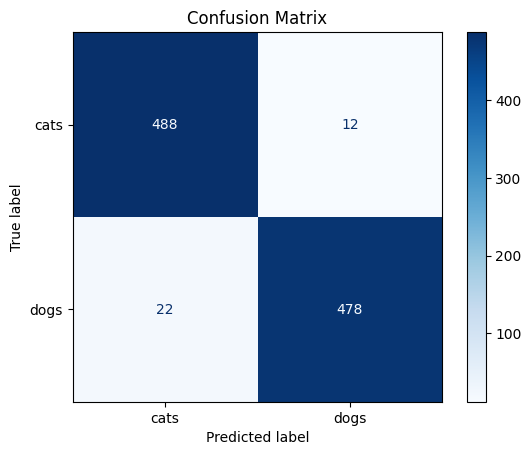

              precision    recall  f1-score   support

        cats       0.96      0.98      0.97       500
        dogs       0.98      0.96      0.97       500

    accuracy                           0.97      1000
   macro avg       0.97      0.97      0.97      1000
weighted avg       0.97      0.97      0.97      1000



In [26]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

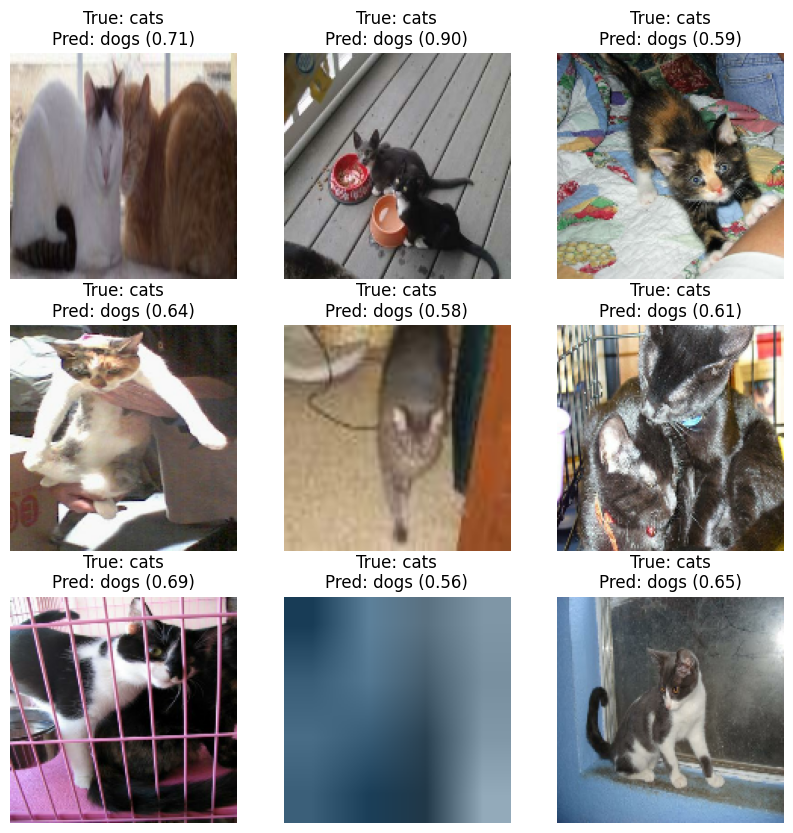

In [27]:
plt.figure(figsize=(10, 10))
shown = 0

for images, labels in val_ds:
    probs = model3.predict(images, verbose=0).flatten()
    preds = (probs > 0.5).astype(int)
    for i in range(len(labels)):
        if preds[i] != labels[i] and shown < 9:
            plt.subplot(3, 3, shown + 1)
            plt.imshow(images[i].numpy().astype("uint8"))
            plt.title(f"True: {class_names[labels[i]]}\nPred: {class_names[preds[i]]} ({probs[i]:.2f})")
            plt.axis("off")
            shown += 1
    if shown >= 9:
        break
plt.show()

Saving cat image.jpg to cat image.jpg


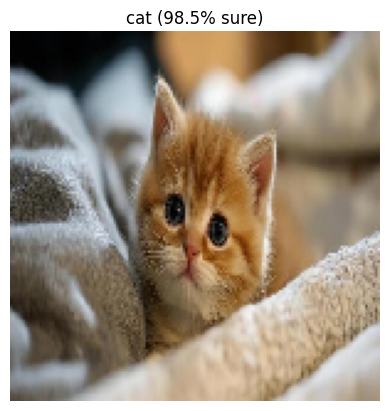

In [28]:
from google.colab import files

uploaded = files.upload()   # choose any cat or dog photo from your computer

for fname in uploaded.keys():
    img = keras.utils.load_img(fname, target_size=(150, 150))
    arr = keras.utils.img_to_array(img)
    arr = np.expand_dims(arr, axis=0)          # shape (1, 150, 150, 3)

    prob = model3.predict(arr, verbose=0)[0][0]
    label = "dog" if prob > 0.5 else "cat"
    confidence = prob if prob > 0.5 else 1 - prob

    plt.imshow(img)
    plt.title(f"{label} ({confidence*100:.1f}% sure)")
    plt.axis("off")
    plt.show()

In [29]:
base_model.trainable = True

# keep the early layers frozen, train only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

model3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),   # very small
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

history_fine = model3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
)

Epoch 1/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 73ms/step - accuracy: 0.8745 - loss: 0.2933 - val_accuracy: 0.9710 - val_loss: 0.0649
Epoch 2/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9160 - loss: 0.2027 - val_accuracy: 0.9670 - val_loss: 0.0678
Epoch 3/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.9350 - loss: 0.1650 - val_accuracy: 0.9700 - val_loss: 0.0631
Epoch 4/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.9415 - loss: 0.1538 - val_accuracy: 0.9770 - val_loss: 0.0585
Epoch 5/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9385 - loss: 0.1474 - val_accuracy: 0.9780 - val_loss: 0.0568
Epoch 6/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9520 - loss: 0.1225 - val_accuracy: 0.9790 - val_loss: 0.0548
Epoch 7/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.9555 - loss: 0.1235 - val_accuracy: 0.9780 - val_loss: 0.0555
Epoch 8/8
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9555 - loss: 0.1113 - val_accuracy: 0.9750 - val_loss

In [37]:
model3.save("cat_dog_classifier.keras")

loaded = keras.models.load_model("cat_dog_classifier.keras")
print("Reloaded OK. Val accuracy:", loaded.evaluate(val_ds, verbose=0)[1])

files.download("cat_dog_classifier.keras")

Reloaded OK. Val accuracy: 0.9750000238418579


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
!pip install -q gradio
import gradio as gr

def predict(img):
    img = img.convert("RGB").resize((150, 150))                  # same size as training
    arr = np.expand_dims(np.array(img, dtype="float32"), axis=0)  # shape (1, 150, 150, 3)
    prob_dog = float(model3.predict(arr, verbose=0)[0][0])
    return {"dog": prob_dog, "cat": 1 - prob_dog}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=2),
    title="Cat vs Dog Classifier",
    description="Upload a photo of a cat or a dog.",
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c7530924613cde6215.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [36]:
def predict(img):
    img = img.convert("RGB").resize((150, 150))
    arr = np.expand_dims(np.array(img, dtype="float32"), axis=0)
    prob_dog = float(model3.predict(arr, verbose=0)[0][0])

    if 0.35 < prob_dog < 0.65:
        return {"Not sure (cat and dog look equally likely)": 1.0}
    return {"dog": prob_dog, "cat": 1 - prob_dog}

In [39]:
import numpy as np
import gradio as gr
from tensorflow import keras

model = keras.models.load_model("cat_dog_classifier.keras")

def predict(img):
    img = img.convert("RGB").resize((150, 150))
    arr = np.expand_dims(np.array(img, dtype="float32"), axis=0)
    prob_dog = float(model.predict(arr, verbose=0)[0][0])

    if 0.35 < prob_dog < 0.65:
        return {"Not sure (cat and dog look equally likely)": 1.0}
    return {"dog": prob_dog, "cat": 1 - prob_dog}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(num_top_classes=2),
    title="Cat vs Dog Classifier",
    description="Upload a photo of a single cat or dog.",
)

if __name__ == "__main__":
    demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b438eea24b5d3437c0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
